# 02 — EDA inicial de jurisprudência

Análise exploratória dos **609.872 registros legíveis dos 19 arquivos ativos**, alinhada ao notebook 01. Utiliza os agregados integrais da auditoria: tribunais, cobertura temporal, tamanhos de texto, completude, categorias declaradas e repetições, sem expor textos ou dados de partes.

O inventário histórico preserva os 20 arquivos recebidos do escopo ativo. A cópia oficial adicional de 50.000 registros STF está separada.

Os indicadores de texto e duplicação referem-se à versão anterior ao mascaramento. A etapa 03 já gerou o CSV/Parquet com CPFs mascarados; esta EDA informa seus resultados sem reaplicar a transformação. STF não equivale automaticamente a conteúdo trabalhista, e `train` nos nomes dos arquivos não define a partição do experimento.

## 1. Importação de bibliotecas e configuração do ambiente

Importação de bibliotecas, localização da raiz do projeto e leitura dos relatórios já calculados. Use o kernel **Python (.venv lex_clt.ai)**. `EXECUTAR_EDA=False` mantém a leitura dos resultados salvos; a integridade dos agregados de origem é conferida por hash.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.display import Markdown
ROOT_JUR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
               if (p/'src/jurisprudencia/eda.py').is_file()),None)
if ROOT_JUR is None:raise FileNotFoundError('Raiz do projeto não encontrada.')
if str(ROOT_JUR) not in sys.path:sys.path.insert(0,str(ROOT_JUR))

from src.jurisprudencia import eda,audit,report
EXECUTAR_EDA=False
if EXECUTAR_EDA:
    EDA_DIR,resumo_eda=eda.run(ROOT_JUR)
else:
    pointer=json.loads((ROOT_JUR/'reports/jurisprudencia/eda/eda_ativa.json').read_text(encoding='utf-8'))
    EDA_DIR=(ROOT_JUR/pointer['pasta']).resolve()
    if not EDA_DIR.is_relative_to((ROOT_JUR/'reports/jurisprudencia/eda').resolve()):raise ValueError('Pasta inválida.')
    resumo_eda=json.loads((EDA_DIR/'resumo_eda.json').read_text(encoding='utf-8'))
AUDIT_DIR,_,_=report.load(ROOT_JUR)
for name,expected in resumo_eda['base_arquivos_sha256'].items():
    if audit.hash_file(AUDIT_DIR/name)!=expected:raise ValueError('Agregados de origem mudaram; execute novamente a EDA.')
print('EDA:',EDA_DIR)

# Resumo de apresentação do escopo ativo
from src.jurisprudencia import presentation
resumo_eda,ARQUIVOS_ATIVOS_EDA=presentation.eda_scope(ROOT_JUR,resumo_eda)
display(pd.Series({k:v for k,v in resumo_eda.items() if not isinstance(v,dict)},name='resultado_escopo_ativo').to_frame())


EDA: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\eda\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\3343f1a3114257d9cf233ccf4625c8188232a1cfa05980076d83587e69d8f17f


,resultado_escopo_ativo
executado_em_utc,2026-11-14T00:53:29.036274+00:00
inventario_sha256,71714343f9fd896da188fc14ed120ae9b8343b744455f4...
codigo_eda_sha256,3343f1a3114257d9cf233ccf4625c8188232a1cfa05980...
registros_legiveis,609872
arquivos_nao_integralmente_lidos,0
media_caracteres_global_ponderada,20232.689279
registros_com_ano_interpretavel,590206
julgamento_ou_assinatura,Ano de assinatura é alternativa identificada d...
quantis_globais,Não calculados: quantis por arquivo não podem ...
categorias,Top 30 declarado por arquivo; sem normalização...


## 2. Importação dos dados e definição do escopo

Carregamento do contexto e dos manifestos das etapas anteriores e posteriores. A EDA usa os agregados dos **19 arquivos ativos**, com 609.872 registros legíveis. O inventário histórico é preservado e a cópia adicional de 50.000 registros STF continua separada.

In [2]:
contexto_atual=presentation.context(ROOT_JUR)
display(Markdown(presentation.eda_status_markdown(contexto_atual)))


## Escopo e proteção de dados

A EDA apresenta **19 arquivos ativos e 609.872 registros legíveis**, alinhados ao notebook 01. O arquivo local ilegível foi excluído da análise ativa; os 20 arquivos recebidos continuam documentados no inventário histórico. A exclusão não removeu registros legíveis nem alterou as proporções por tribunal.

Foram confirmadas por hash e tamanho as origens de **18 dos 19 arquivos ativos**. A origem individual de `jurisprudencias_tst.json` continua pendente. A cópia oficial adicional de **50.000 registros STF permanece separada**, fora destas estatísticas.

Na etapa 03 foi concluído o mascaramento de CPFs em uma derivada CSV/Parquet de 609.872 registros: 5,695 registros alterados e 13,294 substituições. O CSV foi relido integralmente, sem resíduos dos padrões tratados. Os originais permanecem separados; outros dados pessoais ainda exigem revisão.

**Versão analisada:** os gráficos históricos descrevem os dados anteriores ao mascaramento. O painel automático adicional apresenta a cobertura e os tamanhos pós-PLN. Os vínculos e as partições foram recalculados e conferidos sobre essa versão.

A triagem temática usa metadados, sem classificar juridicamente o conteúdo dos textos. A pertinência trabalhista dos documentos STF permanece sujeita a revisão. Detalhes em [03 — Limpeza e proteção](03_limpeza_estruturacao_jurisprudencia.ipynb), [Revisão](03_limpeza_estruturacao_jurisprudencia.ipynb#verificacao-automatica) e [Origens](03_limpeza_estruturacao_jurisprudencia.ipynb#fontes-proveniencia).


## 3. Limpeza estrutural e unificação dos textos

**Executada no notebook 03; aqui é documentada para orientar a leitura do fluxo.** A estruturação padronizou campos e tipos, associou tribunal, processo, datas e origem e selecionou o texto principal disponível, distinguindo inteiro teor, ementa e texto de busca.

A unificação significa um esquema comum por registro, com linhagem. Não concatena decisões diferentes nem transforma uma ementa em inteiro teor. As versões originais continuam separadas e as diferenças entre julgamento, publicação e assinatura são preservadas.

## 4. Limpeza leve e normalização conservadora, preservando o texto jurídico (PLN)

**Executada na etapa de limpeza do notebook 03; os resultados auditados são carregados abaixo.**

### Critérios da limpeza leve e normalização conservadora (PLN)

| Etapa | Procedimento e preservação |
| --- | --- |
| **Limpar a formatação** | Remover HTML reconhecido e converter entidades, inclusive `&nbsp;` sem tags. Corrigir espaços repetidos, mantendo limites de parágrafos, listas e títulos; conservar a numeração das listas ordenadas reconhecidas. |
| **Normalizar caracteres** | Aplicar Unicode **NFC** e uniformizar quebras de linha. Preservar acentos, pontuação, números e referências como `art. 482`, `§ 2º` e `Súmula 331`. |
| **Tratar ruído de extração** | Identificar linhas recorrentes de início/fim como candidatas a cabeçalho/rodapé, sem removê-las automaticamente. Sinalizar palavras partidas. Unir partes somente com origem PDF confirmada e palavra aprovada; preservar hífens legítimos, como em `pré-judicial`. Neste lote, a origem PDF não está confirmada, portanto não há junção automática. |
| **Auditar o resultado** | Contar vazios, ausências e duplicatas exatas. Comparar amostras antes/depois por invariantes e marcadores jurídicos. Preservar `ementa` e `inteiro_teor` separados; texto de busca e variantes também ficam identificados. |

**Evitar remover stopwords, acentos ou pontuação.** “Não” e “salvo” podem mudar o sentido da decisão. Esta etapa não faz lematização, stemming, classificação temática ou reescrita jurídica.

O processamento parte da derivada com CPFs mascarados. A decodificação HTML pode revelar números antes codificados, por isso o mascaramento é reaplicado aos textos normalizados. O original e a derivada anterior permanecem separados. As amostras reais são salvas somente em dados processados ignorados pelo Git: podem conter nomes ou outros dados pessoais, e não são exibidas nos relatórios do notebook.

Os candidatos a cabeçalho/rodapé são repetições exatas nas duas primeiras/últimas linhas, entre 8 e 200 caracteres, presentes em pelo menos 10 documentos. Isso é triagem, não prova de ruído. As regras preservam esses trechos e registram alertas computacionais, sem exclusão automática de repetições.

In [3]:
from src.jurisprudencia import light_nlp
PLN_REPORT,resumo_pln=light_nlp.load(ROOT_JUR)
assert resumo_pln['registros']==contexto_atual['structured']['registros']
assert resumo_pln['base_cpf_csv_sha256']==contexto_atual['cpf_protection']['csv_sha256']
assert resumo_pln['validacao_csv']['registros_csv_relidos']==resumo_pln['registros']
assert resumo_pln['validacao_csv']['residuos_padrao_cpf']==0
assert 'ementa' in resumo_pln['colunas'] and 'inteiro_teor' in resumo_pln['colunas']
assert (ROOT_JUR/resumo_pln['csv']).exists()
from src.jurisprudencia.pln_dataset import open_dataset as open_pln_dataset
assert open_pln_dataset(ROOT_JUR).count_rows()==resumo_pln['registros']
display(pd.Series(resumo_pln['indicadores'],name='auditoria_pln_leve').to_frame())
display(pd.Series(resumo_pln['operacoes'],name='campos_com_operacao').to_frame())
display(pd.read_csv(PLN_REPORT/'duplicatas_exatas.csv'))
bordas_pln=pd.read_csv(PLN_REPORT/'cabecalhos_rodapes_candidatos.csv')
display(bordas_pln.head(20))
print('Candidatos recorrentes por fingerprint, sem texto ou nomes; não removidos:',len(bordas_pln))
print('Amostras comparadas automaticamente:',resumo_pln['amostras'],'| reduções dos marcadores monitorados:',resumo_pln['indicadores']['amostras_com_marcadores_juridicos_reduzidos_revisar'])
print('Amostra antes/depois (não exibida):',ROOT_JUR/resumo_pln['amostra_local'])
print('CSV após PLN:',ROOT_JUR/resumo_pln['csv'])
print('Leitura somente dos shards: open_pln_dataset(ROOT_JUR); amostra antes/depois excluída do corpus.')
print('Relatório:',PLN_REPORT)
print(resumo_pln['politica_pdf'])
print('Limites: PLN de formato e regras documentadas; não comprova mérito jurídico, integralidade de documentos ou anonimização completa.')
# Exemplos sintéticos: sem nomes, números de processo ou CPFs reais.
exemplos_pln=['Na\u0303o&nbsp;  aplicar art. 482; § 2º. Salvo Súmula 331.',
              '<h2>Título</h2><p>Não retirar.</p><ul><li>Salvo exceção.</li></ul>',
              'pré-judicial\ntra-\nbalhista']
display(Markdown('**Exemplos sintéticos antes/depois** — a amostra real permanece no arquivo local para revisão.'))
display(pd.DataFrame([{'antes':t,'depois':light_nlp.clean_light(t)[0]} for t in exemplos_pln]))


Candidatos recorrentes por fingerprint, sem texto ou nomes; não removidos: 1537
Amostras comparadas automaticamente: 55 | reduções dos marcadores monitorados: 0
Amostra antes/depois (não exibida): C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee\amostra_antes_depois.parquet
CSV após PLN: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee\jurisprudencia_pln_leve.csv
Leitura somente dos shards: open_pln_dataset(ROOT_JUR); amostra antes/depois excluída do corpus.
Relatório: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee
Origem PDF não confirmada: nenhuma junção automática; correção exige PDF confirmado e vocabulário aprovado.
Limites: PLN de formato e regras documentadas; não comprova mérito jurídi

,auditoria_pln_leve
campos_com_hifen_em_fim_de_linha_revisar,355065
campos_com_entidades_residuais_revisar,3
campos_com_substituicao_unicode_revisar,56
campos_ausentes_inteiro_teor,15730
campos_ausentes_texto_busca,609872
campos_ausentes_texto_outro,609872
campos_ausentes_ementa_alternativa,609872
registros,609872
textos_principais_vazios_antes,0
textos_principais_vazios_depois,0


,campos_com_operacao
espacos_normalizados_paragrafos_preservados,5
entidades_html_convertidas,10


,campo,grupos_exatos_repetidos,ocorrencias_excedentes
0,texto_principal,1602,13607
1,ementa,2560,8833
2,inteiro_teor,966,11483
3,texto_busca,0,0


,posicao,linha_sha256,documentos,status
0,inicio,5eb541bb1f805aeaf120f4debf86e28ed9af106d7acf66...,331831,candidato_repetido_nao_removido
1,fim,fd8ce230fd364ccc541a7b8d908952261bf48fc9524a22...,244413,candidato_repetido_nao_removido
2,fim,d183687f6af2912b8036db4c295e5bbbc55b535d565b57...,89941,candidato_repetido_nao_removido
3,inicio,71886400dfc1df47e5baf8dd0e62207c6a69f03401e277...,68653,candidato_repetido_nao_removido
4,fim,cca232cc3888c2e24079b9524994fd7dead4bfce8be156...,61762,candidato_repetido_nao_removido
5,inicio,ecc6ea357e2f10534ff12ad7a9ca771e81050b4606c484...,32574,candidato_repetido_nao_removido
6,inicio,dd058b2e3d6f158ee7f840262290610b6f0c321bb203e3...,30343,candidato_repetido_nao_removido
7,fim,5b8d7d259935611e40f522bd559fdf3e887d432a9f8cd6...,25557,candidato_repetido_nao_removido
8,fim,d5da50549bf94660397a4d7a5e3cd144f0e05b8598c877...,15428,candidato_repetido_nao_removido
9,inicio,4d7b068daef57c011837843d29296890e1e18b07a23c5d...,11089,candidato_repetido_nao_removido


**Exemplos sintéticos antes/depois** — a amostra real permanece no arquivo local para revisão.

,antes,depois
0,Não&nbsp; aplicar art. 482; § 2º. Salvo Súmu...,Não aplicar art. 482; § 2º. Salvo Súmula 331.
1,<h2>Título</h2><p>Não retirar.</p><ul><li>Salv...,Título\n\nNão retirar.\n\n• Salvo exceção.
2,pré-judicial\ntra-\nbalhista,pré-judicial\ntra-\nbalhista


## 5. Análise exploratória de dados (EDA)

Exploração descritiva de composição por tribunal, tamanhos, cobertura temporal, completude, categorias declaradas e repetições. As proporções usam os registros legíveis, incluindo possíveis sobreposições. Os achados descrevem os arquivos disponíveis; não comprovam representatividade das demandas trabalhistas.

### 5.1. Composição, volume e tribunais utilizados

Distribuição por tribunal e inventário dos 19 arquivos ativos. O arquivo ilegível consta apenas no histórico. As contagens não representam necessariamente decisões jurídicas únicas.

In [4]:
display(pd.read_csv(EDA_DIR/'composicao_tribunais.csv'))
inventario_ativo_eda=pd.read_csv(AUDIT_DIR/'inventario_arquivos.csv')
inventario_ativo_eda=inventario_ativo_eda[inventario_ativo_eda['arquivo'].isin(ARQUIVOS_ATIVOS_EDA)].copy()
assert len(inventario_ativo_eda)==19
assert inventario_ativo_eda['registros_lidos'].sum()==resumo_eda['registros_legiveis']
display(inventario_ativo_eda[['arquivo','status','registros_lidos','features_raiz']])


,tribunal,registros_lidos,proporcao_registros_legiveis
0,STF,148311,0.243184
1,TRT-10,30486,0.049988
2,TRT-13,15730,0.025792
3,TRT-17,37975,0.062267
4,TST,375681,0.616000
5,não identificado,1689,0.002769


,arquivo,status,registros_lidos,features_raiz
0,jurisprudencia_trt13.jsonl,concluido,15730,18
1,jurisprudencias_tst.json,concluido,10000,2
2,train-00001.parquet,concluido,50000,17
3,train-00000.parquet,concluido,50000,17
5,train-00005.parquet,concluido,50000,17
6,part-00000.parquet,concluido,366,25
7,part-00000 (1).parquet,concluido,18780,25
8,part-00000 (3).parquet,concluido,1114,25
9,part-00000 (2).parquet,concluido,17714,25
10,part-00000 (4).parquet,concluido,1,25


### 5.2. Tamanho dos textos e cobertura temporal

Os tamanhos estão em caracteres, não tokens. A média global é ponderada; medianas e p95 permanecem por arquivo, sem calcular quantis globais pela média dos quantis locais. O ano pode ser de julgamento ou assinatura, conforme o campo disponível, sem equiparar as duas datas.

In [5]:
display(presentation.eda_frame(EDA_DIR/'texto_por_arquivo.csv',ARQUIVOS_ATIVOS_EDA))
display(pd.read_csv(EDA_DIR/'distribuicao_anual.csv'))
display(pd.read_csv(EDA_DIR/'histograma_texto.csv'))


,arquivo_id,arquivo,status,registros,n,min,media,max,p50,p95
0,f01,jurisprudencia_trt13.jsonl,concluido,15730,15730,56.0,1827.034393,10545.0,1375.0,4283.10
1,f02,jurisprudencias_tst.json,concluido,10000,10000,19.0,19.000000,19.0,19.0,19.00
2,f03,train-00001.parquet,concluido,50000,50000,70.0,9331.789460,2514779.0,2311.5,36810.65
3,f04,train-00000.parquet,concluido,50000,50000,68.0,20120.892620,3038189.0,9565.5,57017.25
5,f06,train-00005.parquet,concluido,50000,50000,70.0,10692.593160,1727225.0,6641.0,31678.20
6,f07,part-00000.parquet,concluido,366,366,2557.0,20576.871585,104678.0,14504.0,56380.75
7,f08,part-00000 (1).parquet,concluido,18780,18780,1520.0,21113.691480,240287.0,14041.5,62804.15
8,f09,part-00000 (3).parquet,concluido,1114,1114,2663.0,19663.962298,129524.0,15341.0,51766.45
9,f10,part-00000 (2).parquet,concluido,17714,17714,1224.0,20640.368691,377682.0,14019.0,58723.20
10,f11,part-00000 (4).parquet,concluido,1,1,10265.0,10265.000000,10265.0,10265.0,10265.00


,ano,registros
0,1998,4
1,1999,9996
2,2000,6693
3,2001,10767
4,2002,9275
5,2003,9612
6,2004,100
7,2005,100
8,2006,100
9,2007,99


,faixa_caracteres,registros
0,vazio,0
1,<80,10041
2,80-499,6342
3,500-1999,34680
4,2000-9999,189835
5,>=10000,368974


### 5.3. Completude, classes e tipos declarados

Ausências lógicas consideram os campos alternativos disponíveis; não se somam ausências de colunas como se fossem documentos diferentes. As categorias são top 30 por campo/arquivo, sem harmonização jurídica. Não permitem deduzir uma distribuição conjunta tribunal × ano não medida.

In [6]:
display(presentation.eda_frame(EDA_DIR/'ausencias_logicas_por_arquivo.csv',ARQUIVOS_ATIVOS_EDA))
display(presentation.eda_frame(EDA_DIR/'categorias_top30_por_arquivo.csv',ARQUIVOS_ATIVOS_EDA).head(80))
display(pd.read_csv(EDA_DIR/'indicadores_agregados.csv'))


,arquivo_id,arquivo,indicador,registros_com_ausencia,denominador,proporcao_ausencia
0,f01,jurisprudencia_trt13.jsonl,sem_texto_principal,0,15730,0.00000
1,f01,jurisprudencia_trt13.jsonl,identificador_documental_ausente,0,15730,0.00000
2,f01,jurisprudencia_trt13.jsonl,processo_ausente,0,15730,0.00000
3,f01,jurisprudencia_trt13.jsonl,julgamento_ou_assinatura_ausente,0,15730,0.00000
4,f01,jurisprudencia_trt13.jsonl,publicacao_ausente,15730,15730,1.00000
...,...,...,...,...,...,...
95,f20,part-00000 (9).parquet,sem_texto_principal,0,30486,0.00000
96,f20,part-00000 (9).parquet,identificador_documental_ausente,0,30486,0.00000
97,f20,part-00000 (9).parquet,processo_ausente,0,30486,0.00000
98,f20,part-00000 (9).parquet,julgamento_ou_assinatura_ausente,19665,30486,0.64505


,arquivo_id,feature,categoria_declarada,ocorrencias,escopo
0,f01,tribunal,TRT13,15730,Top 30 por arquivo; não representa domínio com...
1,f01,classe,ROT,8332,Top 30 por arquivo; não representa domínio com...
2,f01,classe,AP,3387,Top 30 por arquivo; não representa domínio com...
3,f01,classe,EDCiv,2313,Top 30 por arquivo; não representa domínio com...
4,f01,classe,RORSum,840,Top 30 por arquivo; não representa domínio com...
...,...,...,...,...,...
75,f04,base,novo_informativo,523,Top 30 por arquivo; não representa domínio com...
76,f04,base,jurisprudencia,305,Top 30 por arquivo; não representa domínio com...
77,f04,base,sumulas,3,Top 30 por arquivo; não representa domínio com...
78,f04,classe,RECURSO EXTRAORDINÁRIO COM AGRAVO,15212,Top 30 por arquivo; não representa domínio com...


,indicador,ocorrencias,denominador_registros_legiveis
0,campo_partes_ou_contato_preenchido,144824,609872
1,conflito_tribunal_em_campos,0,609872
2,hash_texto_declarado_conferido,449872,609872
3,hash_texto_nao_coincide_com_candidatos_brutos,0,609872
4,identificador_documental_ausente,0,609872
5,julgamento_ou_assinatura_ausente,19666,609872
6,julgamento_ou_assinatura_futura,0,609872
7,julgamento_ou_assinatura_nao_interpretavel,0,609872
8,processo_ausente,1371,609872
9,processo_formato_cnj_detectado,450329,609872


### 5.4. Triagem temática por metadados e pertinência trabalhista

Jurisdição trabalhista e ramo declarado são evidências para revisão. A simples presença de um documento STF ou de palavras jurídicas não confirma pertinência ao RAG trabalhista. Esta triagem não é classificação semântica do conteúdo.

STF no lote original:


**Triagem temática por metadados — aprofundamento inicial.** Jurisdição trabalhista e ramo declarado são evidências para revisão, não aprovação do conteúdo. Documentos STF sem evidência temática permanecem pendentes. Não foi feita classificação semântica dos textos.

,tribunal,triagem_tematica,registros
0,STF,pertinencia_nao_confirmada,148311
1,TRT-10,jurisdicao_trabalhista_revisar_conteudo,30486
2,TRT-13,jurisdicao_trabalhista_revisar_conteudo,15730
3,TRT-17,jurisdicao_trabalhista_revisar_conteudo,37975
4,TST,jurisdicao_trabalhista_revisar_conteudo,375681
5,não identificado,pertinencia_nao_confirmada,1689


,tribunal,triagem_tematica,registros
0,STF,pertinencia_nao_confirmada,148311


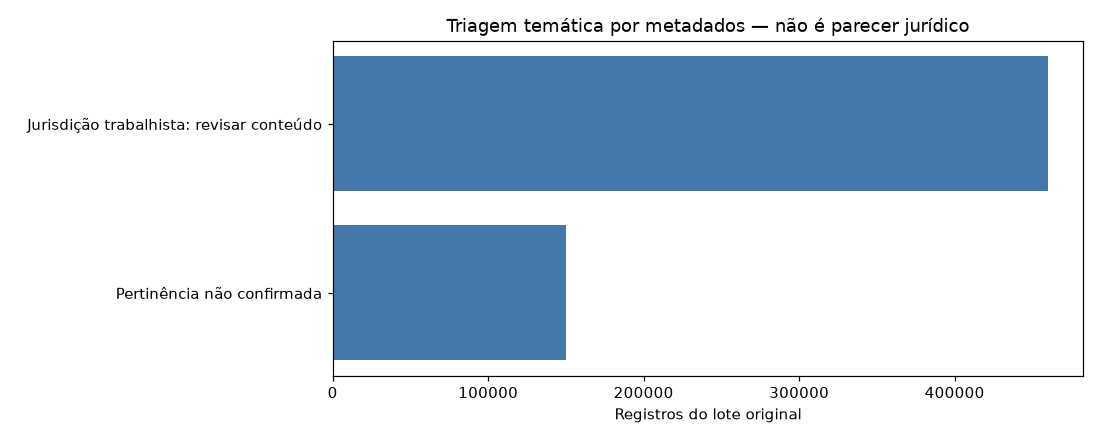

In [7]:
# Triagem temática por metadados; não é classificação jurídica do conteúdo.
tema_atual=pd.read_csv(contexto_atual['review_dir']/'tribunais_tema.csv')
assert int(tema_atual['registros'].sum())==contexto_atual['audited']['registros_lidos']
display(Markdown('**Triagem temática por metadados — aprofundamento inicial.** Jurisdição trabalhista e ramo declarado são evidências para revisão, não aprovação do conteúdo. Documentos STF sem evidência temática permanecem pendentes. Não foi feita classificação semântica dos textos.'))
display(tema_atual)
print('STF no lote original:')
display(tema_atual[tema_atual['tribunal'].eq('STF')])
fig,ax=plt.subplots(figsize=(10,4))
totais_tema=tema_atual.groupby('triagem_tematica')['registros'].sum().sort_values()
nomes={'jurisdicao_trabalhista_revisar_conteudo':'Jurisdição trabalhista: revisar conteúdo','ramo_trabalhista_declarado_revisar':'Ramo trabalhista declarado: revisar','pertinencia_nao_confirmada':'Pertinência não confirmada'}
ax.barh([nomes.get(k,k) for k in totais_tema.index],totais_tema.values,color='#4477aa')
ax.set_xlabel('Registros do lote original');ax.set_title('Triagem temática por metadados — não é parecer jurídico')
fig.tight_layout();fig.savefig(EDA_DIR/'triagem_tematica_metadados.png',dpi=140);plt.show()


### Classificação automática de conteúdo e recorte por regras

As verificações abaixo foram executadas sobre o corpus pós-PLN. O relatório distingue evidência declarada, inferências por regras e alertas computacionais. Os resultados são registrados por métodos automáticos; seu alcance não comprova aprovação jurídica ou anonimização integral.

In [8]:
from src.jurisprudencia import automatic_review
AUTO_DIR,resumo_auto=automatic_review.load(ROOT_JUR)
assert resumo_auto['registros']==609872
assert audit.hash_file(ROOT_JUR/resumo_auto['indice'])==resumo_auto['indice_sha256']
display(pd.read_csv(AUTO_DIR/'cobertura_conteudo.csv'))
display(pd.read_csv(AUTO_DIR/'recorte_tribunais.csv'))
display(pd.read_csv(AUTO_DIR/'tamanho_textos.csv'))
print('Tipo declarado é distinguido do inferido; inferência e triagem temática usam regras em até 8.000 caracteres, sem comprovar mérito jurídico.')


Tipo declarado é distinguido do inferido; inferência e triagem temática usam regras em até 8.000 caracteres, sem comprovar mérito jurídico.


,tribunal,tipo_declarado,tipo_inferido,registros
0,STF,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,107464
1,STF,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,36551
2,STF,inteiro_teor_declarado,texto_curto_rotulado_inteiro_teor,4296
3,TRT-10,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,30422
4,TRT-10,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,64
5,TRT-13,ementa,ementa_declarada,15730
6,TRT-17,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,37975
7,TST,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,363894
8,TST,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,1754
9,TST,inteiro_teor_declarado,texto_curto_rotulado_inteiro_teor,10033


,tribunal,triagem,candidato,registros
0,STF,sem_sinal_suficiente_no_prefixo,False,141350
1,STF,sinal_lexical_trabalhista,False,15
2,STF,sinal_lexical_trabalhista,True,6946
3,TRT-10,jurisdicao_trabalhista,True,30486
4,TRT-13,jurisdicao_trabalhista,False,1
5,TRT-13,jurisdicao_trabalhista,True,15729
6,TRT-17,jurisdicao_trabalhista,True,37975
7,TST,jurisdicao_trabalhista,False,10033
8,TST,jurisdicao_trabalhista,True,365648
9,não identificado,sem_sinal_suficiente_no_prefixo,False,1689


,faixa,registros
0,500-1999,34923
1,2000-9999,190067
2,80-499,6501
3,>=10000,368340
4,<80,10041


### 5.5. Sobreposições, repetições e preparação da avaliação

Registro integralmente idêntico, texto igual, chave documental candidata e mesmo processo são critérios diferentes e sobrepostos. Um processo pode conter várias decisões legítimas. A tabela histórica é preservada; os vínculos e as partições da versão pós-PLN foram recalculados no painel automático.

In [9]:
display(pd.read_csv(AUDIT_DIR/'duplicatas_resumo.csv'))

,criterio,grupos_repetidos,registros_nos_grupos,repeticoes_excedentes
0,registro_identico_canonico,0,0,0
1,texto_igual_apos_normalizar_espacos,1712,15520,13808
2,chave_documental_candidata,0,0,0
3,mesmo_processo_nao_implica_duplicata,61599,128612,67013


### 5.6. Gráficos e visualização dos resultados da EDA

Os gráficos descrevem os 609.872 registros do escopo ativo, antes do mascaramento. As barras de ausência e os sinais técnicos não são notas de correção jurídica. Os 50.000 registros STF adicionais não integram estes gráficos.

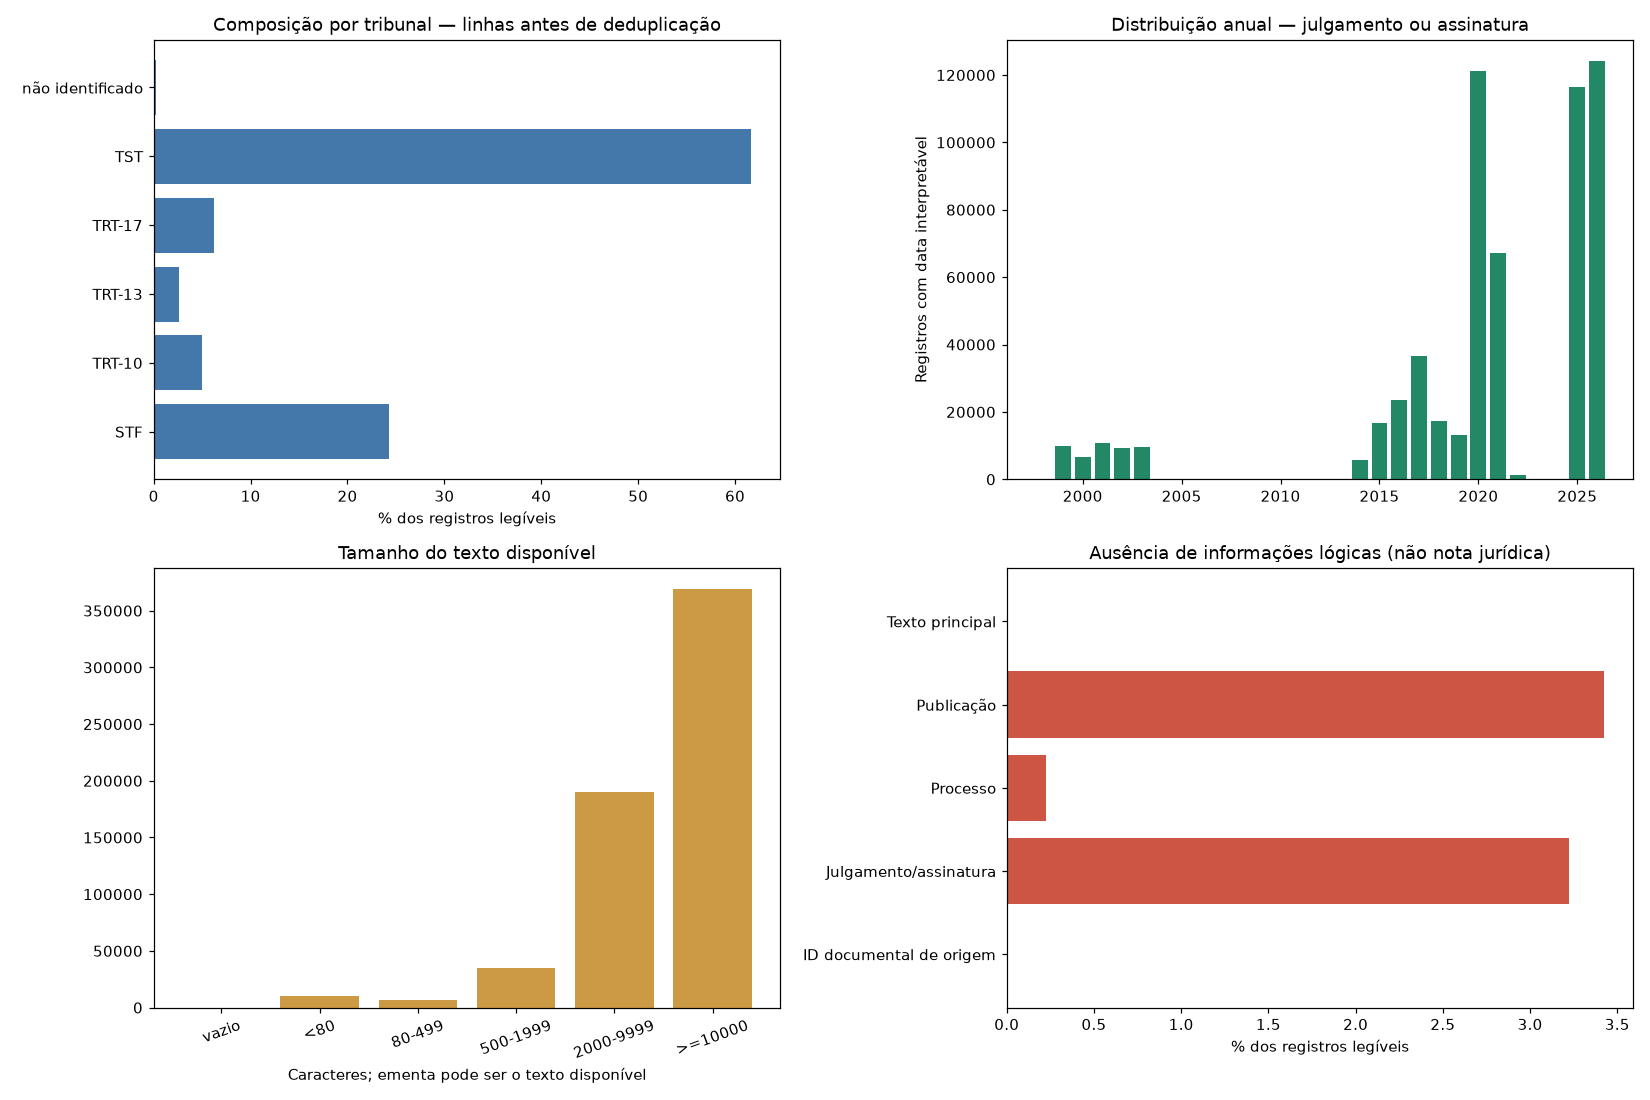

In [10]:
figuras_eda=eda.figures(EDA_DIR)
plt.show()

## 6. SALVANDO O DATASET LIMPO E TRATADO

**Exportação executada no notebook 03.** Foram gerados CSV UTF-8 e shards Parquet separados, com `texto_protegido`, `ementa_protegida` e metadados selecionados. As colunas de texto original não entram nessa derivada.

Este notebook lê os relatórios, sem regravar os dados. A derivada inicial de CPF está em `data/processed/jurisprudencia/protecao_cpf/ativa.json`. A versão após PLN leve está em `data/processed/jurisprudencia/pln_leve/ativa.json`, com `ementa`, `inteiro_teor`, `texto_busca` e variantes identificadas, sem promover ementa a inteiro teor. O CSV após PLN também foi relido integralmente. Os originais e as versões anteriores continuam preservados separadamente.

### 6.1. Proteção de dados pessoais e validação da exportação

Verificação das contagens e do resultado documentado da releitura do CSV protegido. As substituições são ocorrências nos campos tratados, não CPFs distintos ou número de pessoas. Outros dados pessoais e formas de ofuscação não cobertas continuam exigindo revisão.

In [11]:
display(Markdown('**Proteção de CPFs concluída na etapa 03.** Estes resultados são da derivada protegida; os gráficos de texto desta EDA continuam descrevendo a versão original.'))
protecao_cpf_eda=contexto_atual['cpf_protection']
assert protecao_cpf_eda['registros']==resumo_eda['registros_legiveis']
assert protecao_cpf_eda['validacao']['sequencias_compativeis_residuais']==0
display(pd.Series({k:protecao_cpf_eda[k] for k in ('registros','registros_com_mascaramento','sequencias_compativeis_mascaradas','originais_preservados','anonimizado_integralmente')},name='resultado_protecao_cpf').to_frame())
display(pd.Series(protecao_cpf_eda['validacao'],name='validacao_csv_protegido').to_frame())


**Proteção de CPFs concluída na etapa 03.** Estes resultados são da derivada protegida; os gráficos de texto desta EDA continuam descrevendo a versão original.

,resultado_protecao_cpf
registros,609872
registros_com_mascaramento,5695
sequencias_compativeis_mascaradas,13294
originais_preservados,True
anonimizado_integralmente,False


,validacao_csv_protegido
registros_csv_relidos,609872
sequencias_compativeis_residuais,0
colunas_originais_expostas,False
metodo,Releitura integral do CSV UTF-8 com campos mul...


## 7. Análise e avaliação dos resultados

Interpretação dos achados da EDA, da rastreabilidade e da proteção concluída. Trata-se de avaliação descritiva dos dados, não de métricas de desempenho ou de aprovação jurídica de um modelo. A conclusão distingue o que está concluído das revisões ainda necessárias.

In [12]:
from src.jurisprudencia import presentation
conclusao_eda_atual = presentation.conclusion(ROOT_JUR, 'eda', (EDA_DIR/'conclusao_eda.md').read_text(encoding='utf-8'))
(EDA_DIR/'conclusao_eda_atualizada.md').write_text(conclusao_eda_atual,encoding='utf-8')
display(Markdown(conclusao_eda_atual))


# Conclusão da EDA inicial

## Composição e representatividade

O tribunal mais frequente é TST, com 375,681 registros (61.6% das linhas legíveis). A concentração reflete a composição dos arquivos recebidos e não a distribuição de todas as demandas trabalhistas. Registros de arquivos diferentes podem representar versões ou textos repetidos. Não se deve comparar grupos como amostras equivalentes.

O STF abrange temas variados. A jurisdição declarada não substitui classificação temática. O campo ramo_direito, quando disponível, é informação da origem, não uma classificação revisada pelo projeto.

## Textos, datas e completude

Os tamanhos são medidos em caracteres. A média global é ponderada pelas quantidades de registros de cada arquivo; as medianas/p95 continuam por arquivo, sem produzir um quantil global fictício. Há 0 registros sem texto principal segundo as prioridades da auditoria e 199 com marcação HTML detectada.

O ano está disponível em 590,206 registros, usando julgamento ou assinatura conforme a origem. Falhas e ausências de datas devem ser examinadas antes de estudar tendências temporais. As categorias exportadas são top 30 por campo/arquivo; a omissão de uma classe nesse recorte não comprova sua ausência no corpus.

## Escopo e proteção de dados

A EDA apresenta **19 arquivos ativos e 609.872 registros legíveis**, alinhados ao notebook 01. O arquivo local ilegível foi excluído da análise ativa; os 20 arquivos recebidos continuam documentados no inventário histórico. A exclusão não removeu registros legíveis nem alterou as proporções por tribunal.

Foram confirmadas por hash e tamanho as origens de **18 dos 19 arquivos ativos**. A origem individual de `jurisprudencias_tst.json` continua pendente. A cópia oficial adicional de **50.000 registros STF permanece separada**, fora destas estatísticas.

Na etapa 03 foi concluído o mascaramento de CPFs em uma derivada CSV/Parquet de 609.872 registros: 5,695 registros alterados e 13,294 substituições. O CSV foi relido integralmente, sem resíduos dos padrões tratados. Os originais permanecem separados; outros dados pessoais ainda exigem revisão.

**Versão analisada:** os gráficos históricos descrevem os dados anteriores ao mascaramento. O painel automático adicional apresenta a cobertura e os tamanhos pós-PLN. Os vínculos e as partições foram recalculados e conferidos sobre essa versão.

A triagem temática usa metadados, sem classificar juridicamente o conteúdo dos textos. A pertinência trabalhista dos documentos STF permanece sujeita a revisão. Detalhes em [03 — Limpeza e proteção](03_limpeza_estruturacao_jurisprudencia.ipynb), [Revisão](03_limpeza_estruturacao_jurisprudencia.ipynb#verificacao-automatica) e [Origens](03_limpeza_estruturacao_jurisprudencia.ipynb#fontes-proveniencia).


## 8. Diagnóstico e Observações

- Fontes heterogêneas e concentração por tribunal limitam generalizações.
- Ementa, inteiro teor e texto de busca não são equivalentes; datas de assinatura e julgamento também não.
- A origem de 18 dos 19 arquivos ativos está confirmada; o JSON TST continua pendente.
- O mascaramento de CPFs está concluído na derivada protegida; não elimina a necessidade de revisar outros dados pessoais.
- O painel automático registra inferência de conteúdo, sinais temáticos, cópias candidatas e partições pós-PLN. Os rótulos são heurísticos e sua cobertura é documentada.

Os detalhes das filas e critérios de revisão estão no [seção de verificação automática](03_limpeza_estruturacao_jurisprudencia.ipynb#verificacao-automatica); as evidências de origem e licença declarada estão no [seção de fontes e proveniência](03_limpeza_estruturacao_jurisprudencia.ipynb#fontes-proveniencia).

## 9. Integração

**Preparação para integração futura.** Uma seleção aprovada deverá partir do texto protegido do [notebook 03](03_limpeza_estruturacao_jurisprudencia.ipynb), preservar os IDs de linhagem e a fonte e calcular offsets na versão textual efetivamente usada. Chunking, embeddings e indexação dependem das revisões restantes.

Os grupos pós-PLN têm checagem independente dos vínculos conhecidos de texto e processo. Este notebook não indexa os dados, não treina modelos e não altera o RAG legislativo existente.